<a href="https://colab.research.google.com/github/PallaviRajaa/Statistical-Foundation-of-Data-Science/blob/main/StatsA6/StatisticsA6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pyplot
import seaborn as sns

from scipy.stats import ttest_ind, f_oneway, chi2_contingency, pearsonr

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/teachingratings.csv"

ratings_df = pd.read_csv(url)

ratings_df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1


**T-Test: Does gender affect teaching evaluation rates?**


In [3]:
# Separate evaluation scores by gender
female = ratings_df[ratings_df["gender"] == "female"]["eval"]
male = ratings_df[ratings_df["gender"] == "male"]["eval"]

# Calculate mean evaluation scores
print("Female mean:", female.mean())
print("Male mean:", male.mean())

# Perform independent samples t-test
t_stat, p_value = ttest_ind(female, male, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

# Conclusion
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("Gender significantly affects teaching evaluation scores.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in evaluation scores by gender.")

Female mean: 3.901025635156876
Male mean: 4.06902985163589
T-statistic: -3.2667111105019626
P-value: 0.001176103911892759
Reject the null hypothesis.
Gender significantly affects teaching evaluation scores.


If the p-value is less than 0.05, we reject the null hypothesis and conclude that gender is associated with a statistically significant difference in teaching evaluation scores.

If the p-value is greater than or equal to 0.05, we fail to reject the null hypothesis and conclude that there is no statistically significant difference in teaching evaluation scores between male and female instructors.


**ANOVA: Does beauty score for instructors differ by age?**

In [4]:
# Group beauty scores by age
age_groups = ratings_df.groupby("age")["beauty"]

# Create a list of beauty scores for each age group
groups = [group.dropna().values for age, group in age_groups]

# Perform one-way ANOVA
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

# Conclusion
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("Beauty scores differ significantly across age groups.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in beauty scores across age groups.")

F-statistic: 6.64367791343842
P-value: 3.359386321048948e-23
Reject the null hypothesis.
Beauty scores differ significantly across age groups.


If the p-value is less than 0.05, we reject H₀ and conclude that beauty scores differ significantly among at least some of the age groups.

If the p-value is greater than or equal to 0.05, we fail to reject H₀ and conclude that there is no statistically significant difference in beauty scores among the age groups.


**Chi-Square Test: Is there an association between tenure and gender?**

In [5]:
# Create contingency table
contingency_table = pd.crosstab(
    ratings_df["tenure"],
    ratings_df["gender"]
)

print("Contingency Table:")
print(contingency_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

# Conclusion
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("There is a significant association between tenure and gender.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant association between tenure and gender.")

Contingency Table:
gender  female  male
tenure              
no          50    52
yes        145   216
Chi-square statistic: 2.20678166999886
P-value: 0.1374050603563787
Degrees of freedom: 1
Fail to reject the null hypothesis.
There is no significant association between tenure and gender.


If the p-value is less than 0.05, we reject H₀ and conclude that there is a statistically significant association between gender and tenure status.

If the p-value is greater than or equal to 0.05, we fail to reject H₀ and conclude that there is no statistically significant association between gender and tenure status.


**Correlation: Is teaching evaluation score correlated with beauty score?**

In [6]:
import pandas as pd
from scipy.stats import pearsonr

# Load dataset
url = "https://raw.githubusercontent.com/ejvanholm/DataProjects/master/TeachingRatings.csv"
df = pd.read_csv(url)

# Calculate Pearson correlation
r, p_value = pearsonr(df["eval"], df["beauty"])

print("Correlation coefficient:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Correlation coefficient: 0.18903909062278274
P-value: 4.247115507786e-05
Reject H0


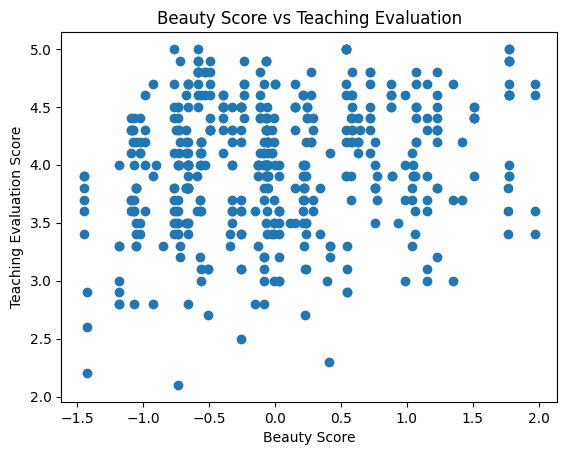

In [7]:
pyplot.scatter(ratings_df["beauty"], ratings_df["eval"])

pyplot.xlabel("Beauty Score")
pyplot.ylabel("Teaching Evaluation Score")
pyplot.title("Beauty Score vs Teaching Evaluation")

pyplot.show()

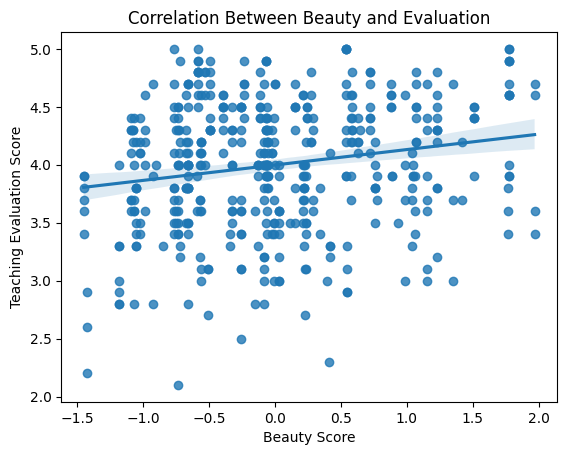

In [8]:
sns.regplot(
    x="beauty",
    y="eval",
    data=ratings_df
)

pyplot.xlabel("Beauty Score")
pyplot.ylabel("Teaching Evaluation Score")
pyplot.title("Correlation Between Beauty and Evaluation")

pyplot.show()